In [16]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
import glob, shutil

zips = glob.glob('/content/drive/MyDrive/**/*dataset_unificado*.zip', recursive=True)
print(zips)

shutil.copy(zips[0], '/content/dataset.zip')
!unzip -q /content/dataset.zip -d /content/dataset
!find /content/dataset -name "data.yaml"

['/content/drive/MyDrive/Cópia de dataset_unificado (1).zip']
/content/dataset/dataset_unificado/data.yaml


In [18]:
!cat /content/dataset/dataset_unificado/data.yaml

train: dataset_unificado/train/images
val: dataset_unificado/val/images
test: dataset_unificado/test/images

nc: 1
names: ['buraco']


In [20]:
!cat /content/dataset/dataset_unificado/data.yaml
!ls /content/dataset/dataset_unificado

train: dataset_unificado/train/images
val: dataset_unificado/val/images
test: dataset_unificado/test/images

nc: 1
names: ['buraco']
data.yaml  test  train	val


In [21]:
yaml_txt = """path: /content/dataset/dataset_unificado
train: train/images
val: val/images
test: test/images

nc: 1
names: ['buraco']
"""
open('/content/data_fix.yaml', 'w').write(yaml_txt)

120

In [22]:
from ultralytics import YOLO

model = YOLO('/content/best (3).pt')

metrics = model.val(
    data='/content/data_fix.yaml',
    split='test',
    plots=True
)

print(f"Precisão:  {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")
print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1365.7±342.1 MB/s, size: 55.2 KB)
val: Scanning /content/dataset/dataset_unificado/test/labels... 247 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 247/247 1.6Kit/s 0.2s
val: New cache created: /content/dataset/dataset_unificado/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 3.9it/s 4.1s
                   all        247        914      0.832      0.794      0.849      0.527
Speed: 2.0ms preprocess, 5.1ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val-3
Precisão:  0.8315
Recall:    0.7943
mAP50:     0.8490
mAP50-95:  0.5272


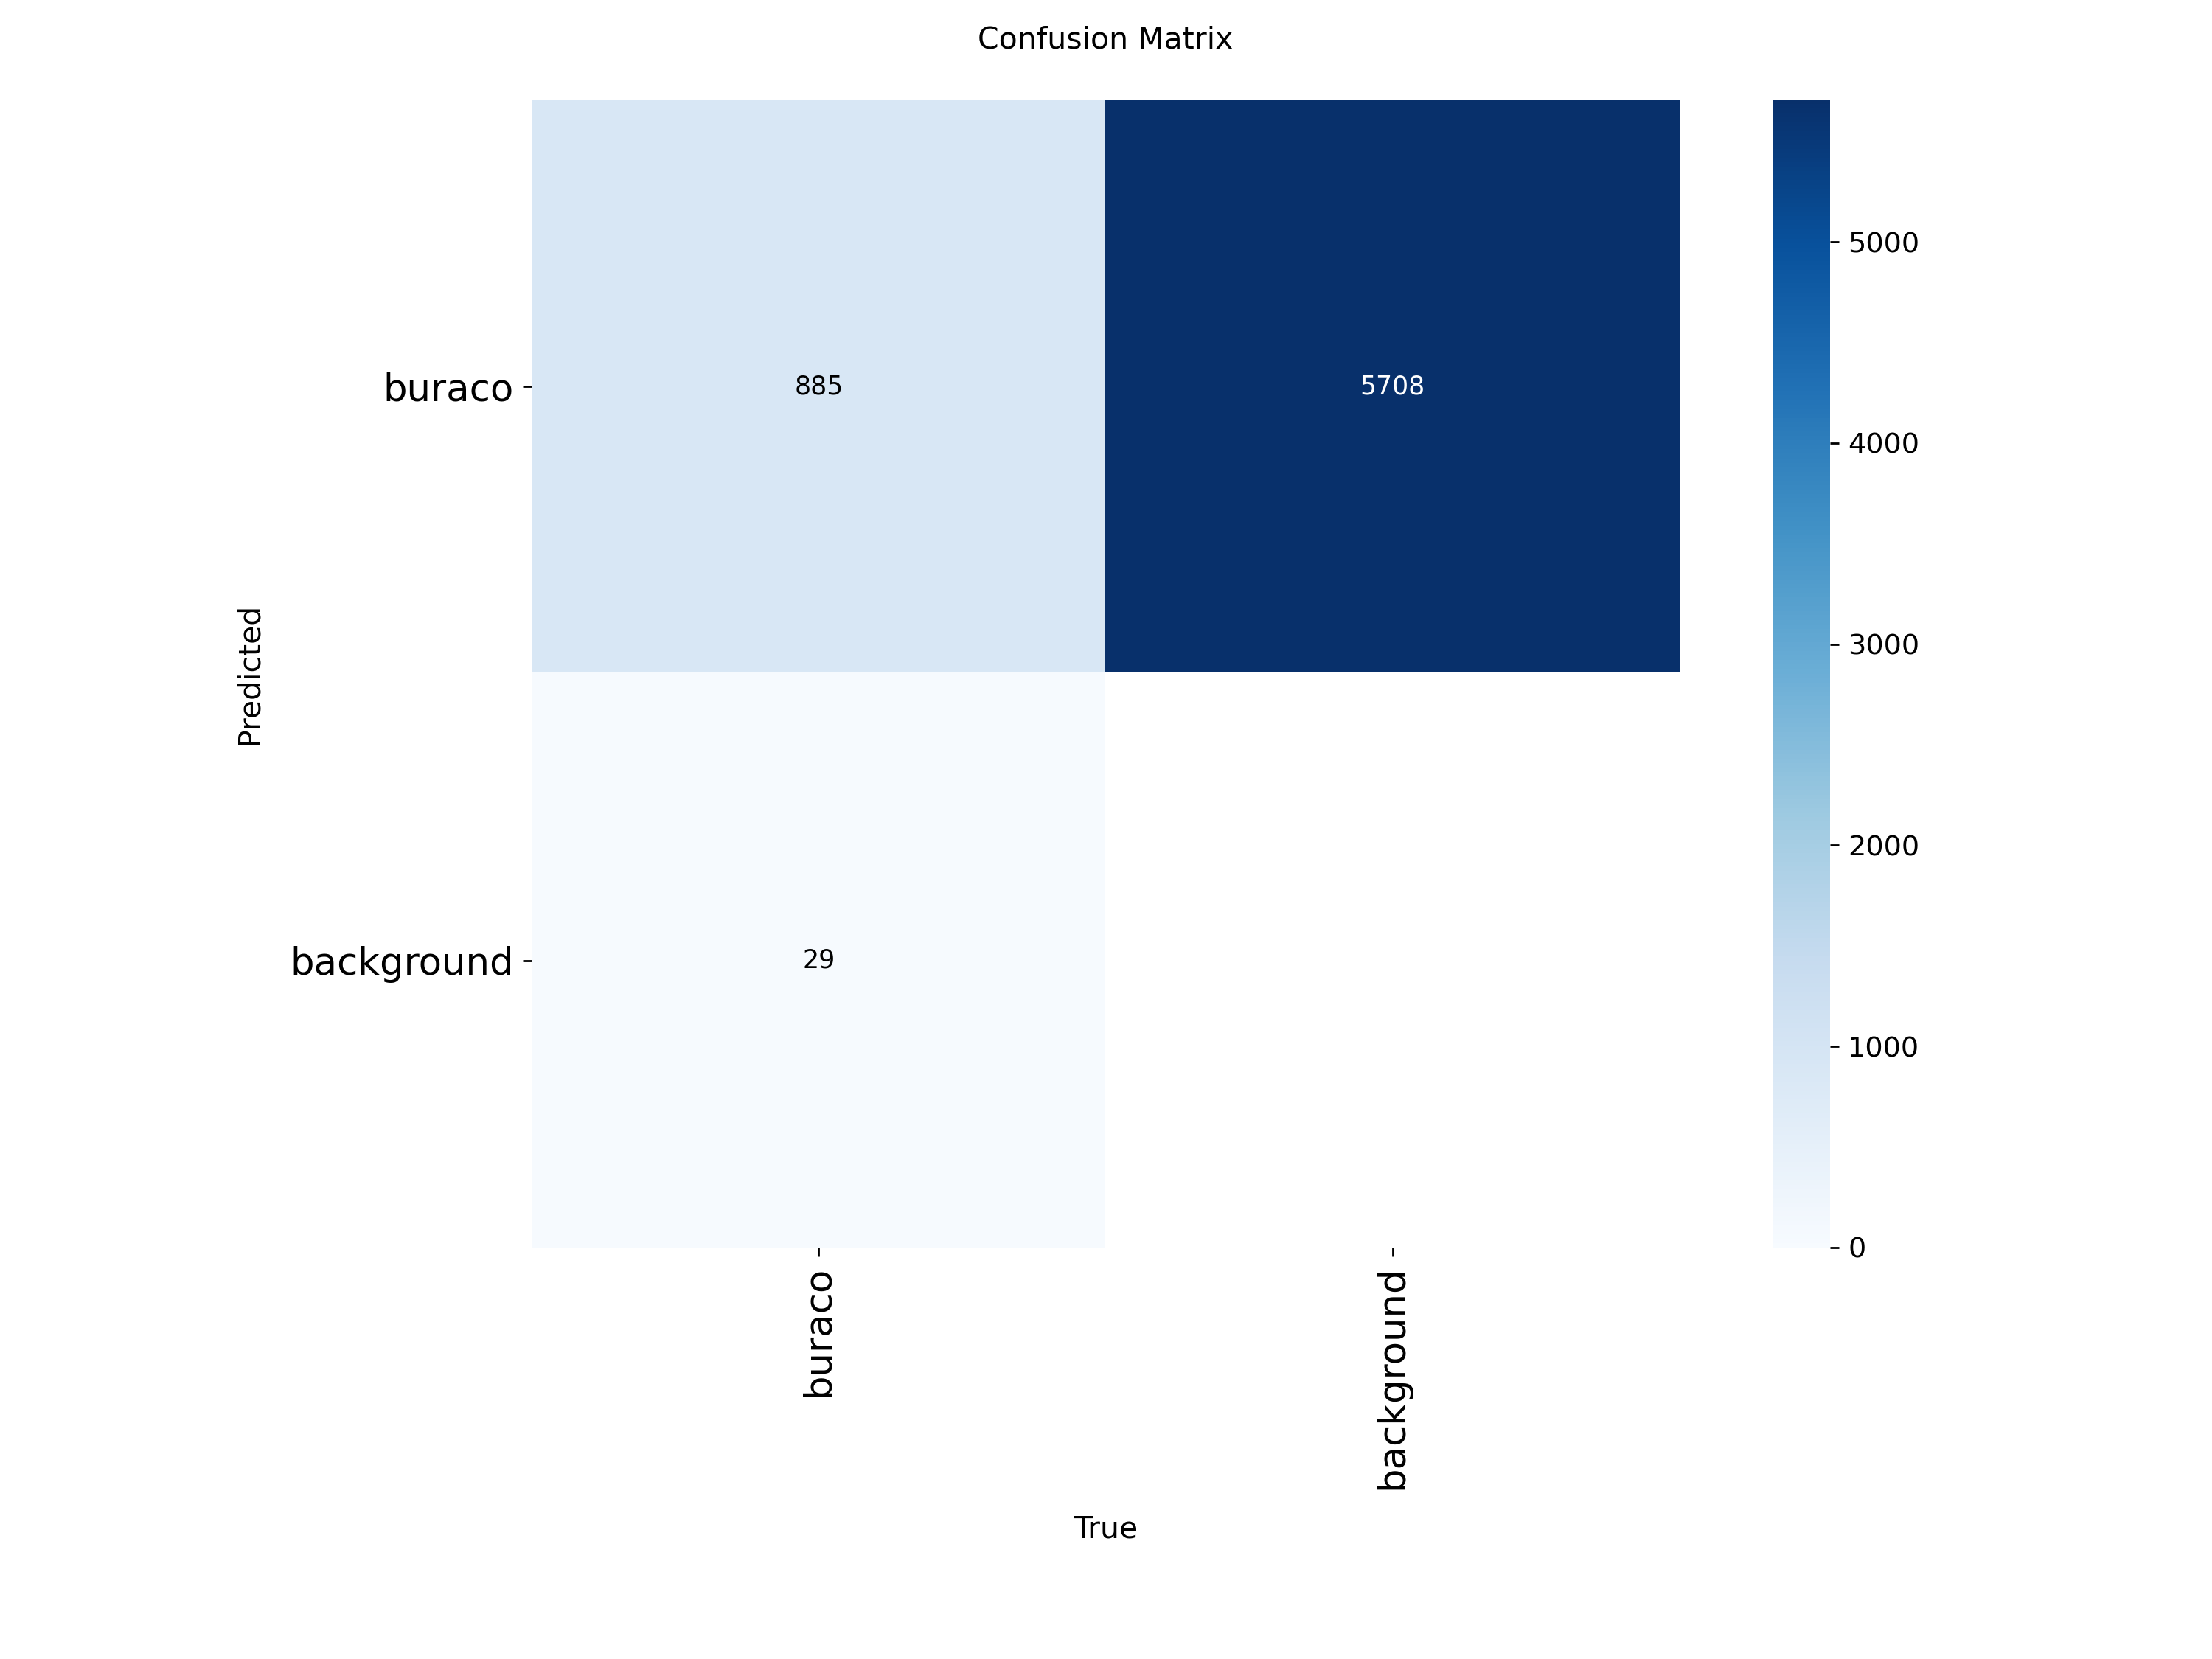

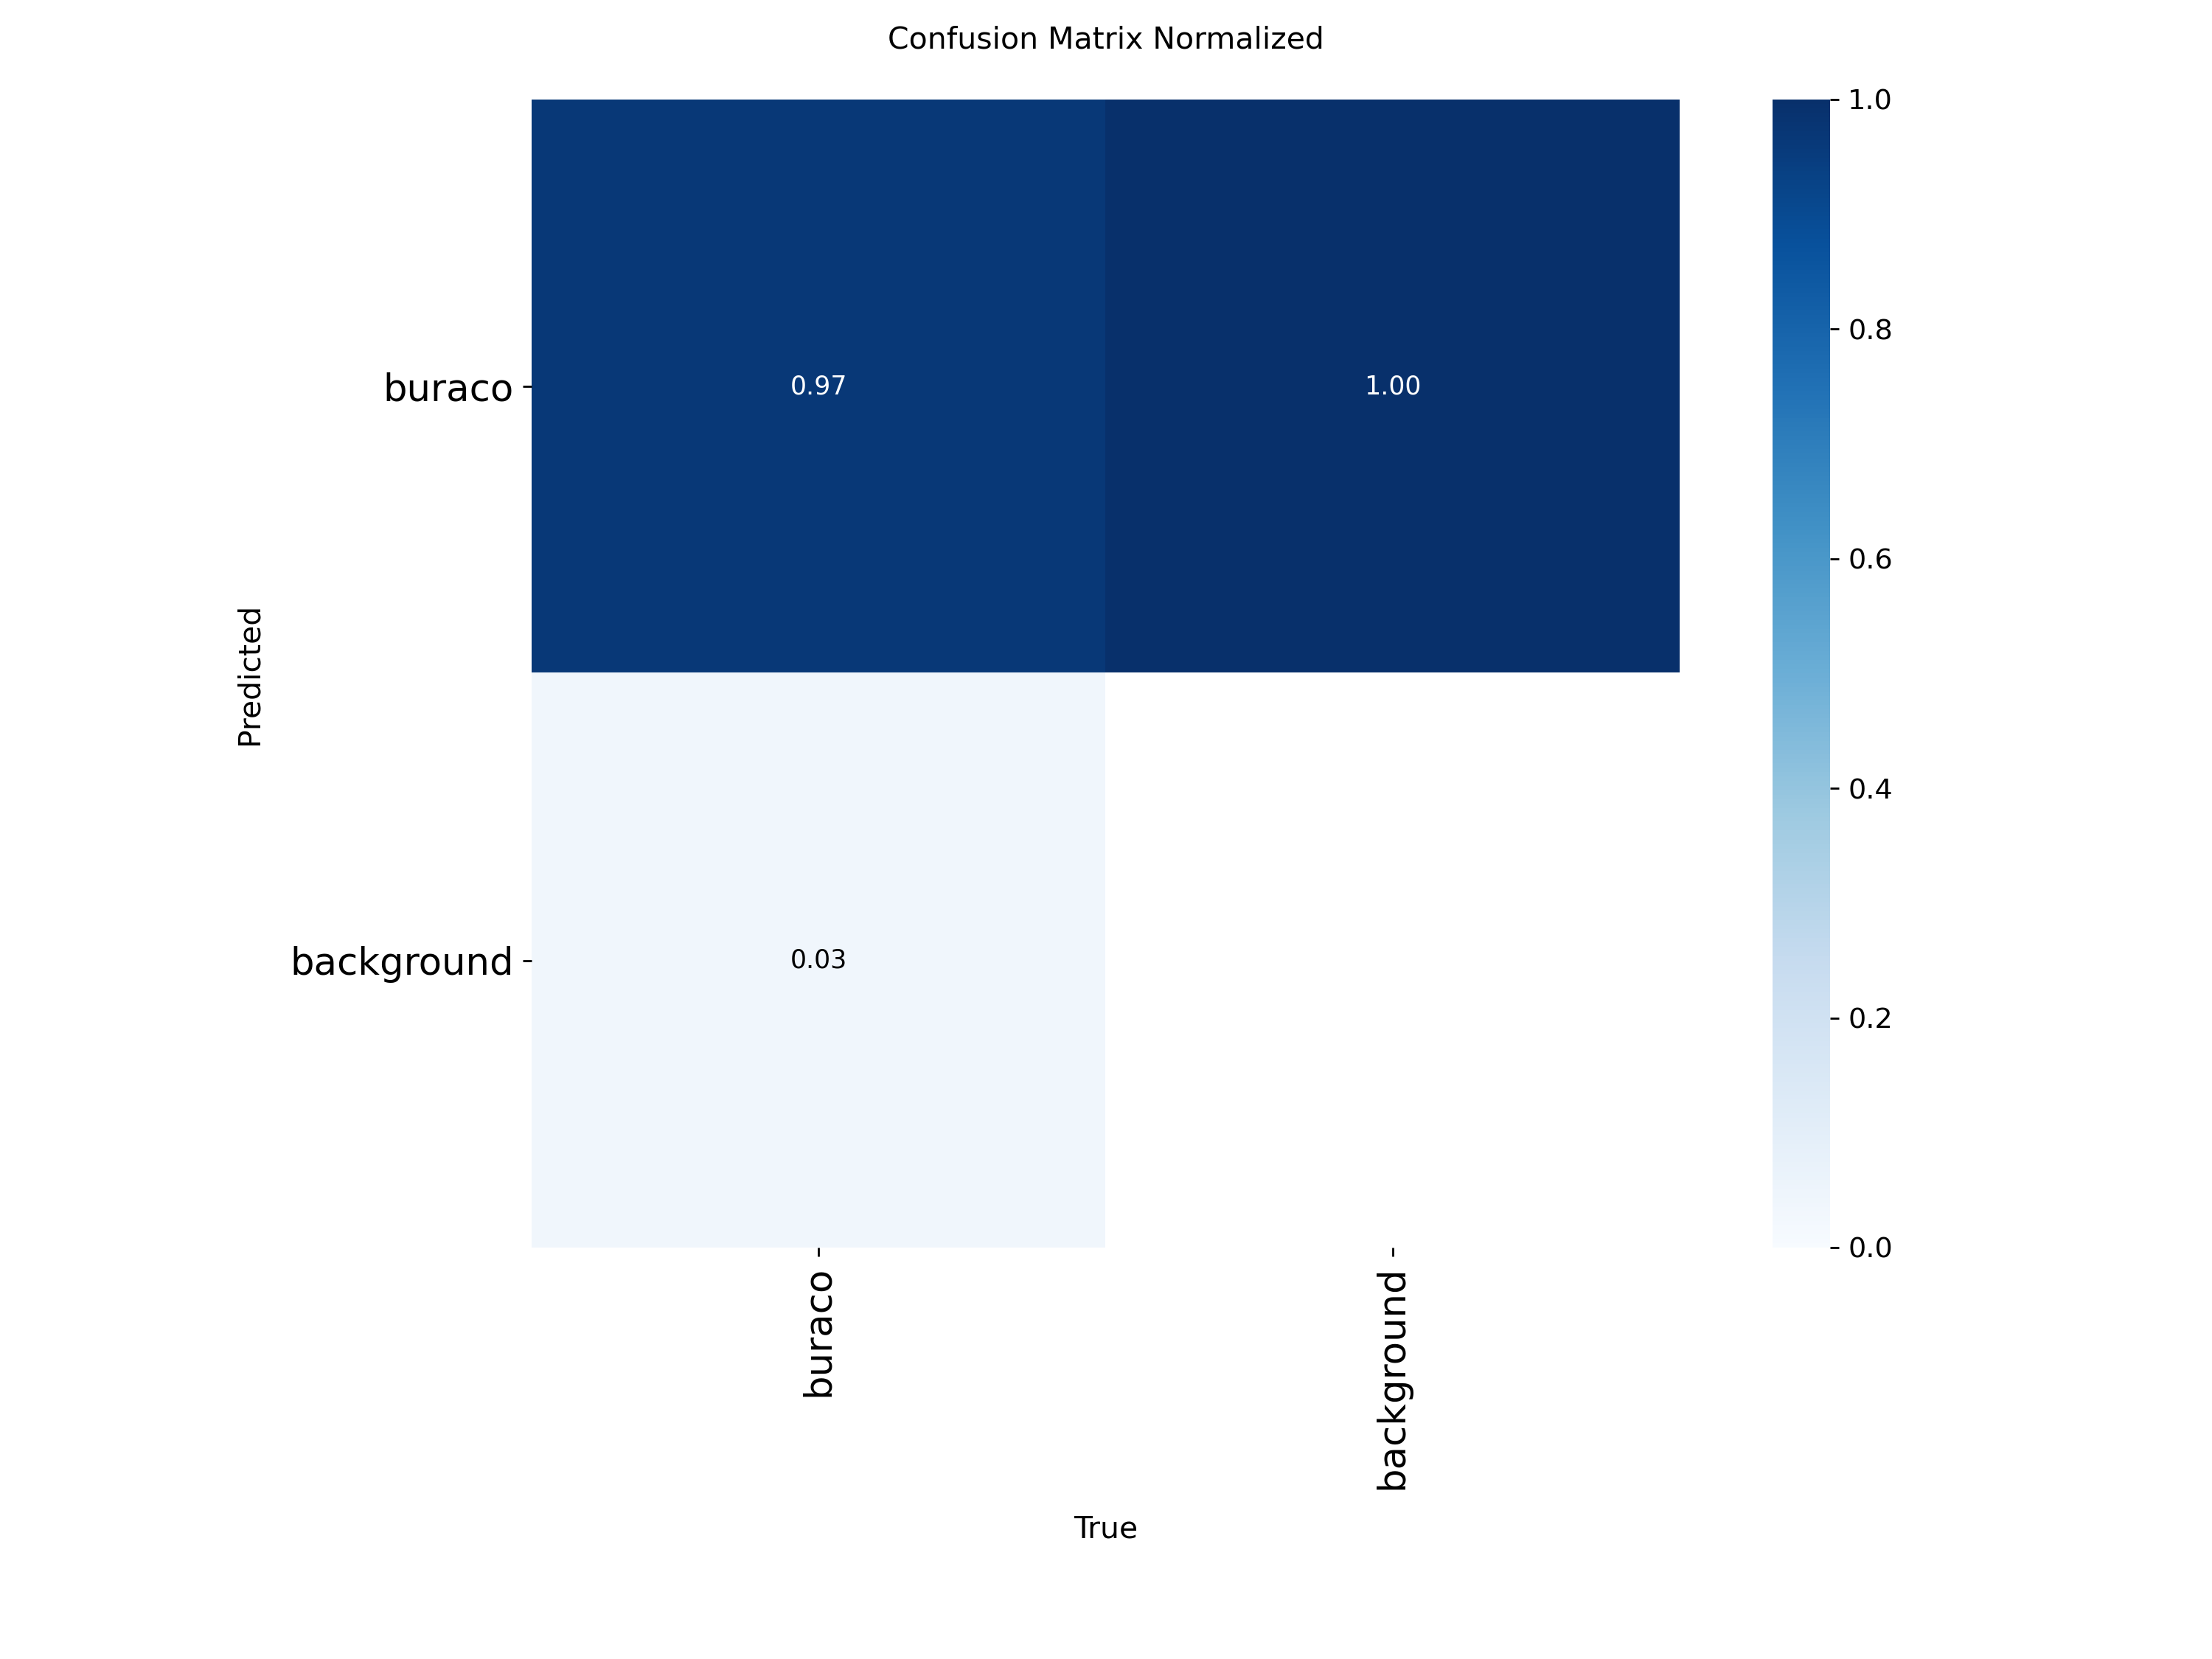

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from IPython.display import Image, display
import shutil
from google.colab import files

for nome in ['confusion_matrix.png', 'confusion_matrix_normalized.png']:
    display(Image(filename=f'{metrics.save_dir}/{nome}'))

shutil.make_archive('metricas', 'zip', metrics.save_dir)
files.download('metricas.zip')

In [24]:
metrics = model.val(
    data='/content/data_fix.yaml',
    split='test',
    plots=True,
    conf=0.25
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1865.1±432.6 MB/s, size: 41.4 KB)
val: Scanning /content/dataset/dataset_unificado/test/labels.cache... 247 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 247/247 74.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.3it/s 3.7s
                   all        247        914      0.832      0.794      0.784      0.494
Speed: 1.6ms preprocess, 4.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /content/runs/detect/val-4


In [28]:
import torch

# 1) Métricas da validação que está na memória
try:
    r = resultados
except NameError:
    r = metrics

print("=== MÉTRICAS DA VALIDAÇÃO ===")
print(f"Precisão: {r.box.mp:.4f} | Recall: {r.box.mr:.4f} | mAP50: {r.box.map50:.4f} | mAP50-95: {r.box.map:.4f}")
print("Salvo em:", r.save_dir)

# 2) Parâmetros efetivos da validação (reconstruídos)
args = {**model.overrides, "rect": True, "mode": "val"}
args.update(imgsz=640, conf=0.25, split="test", plots=True)  # o que você passou
print("\n=== PARÂMETROS EFETIVOS DA VALIDAÇÃO ===")
for k, v in args.items():
    print(f"{k} = {v}")

# 3) Parâmetros do treino (guardados no best.pt)
print("\n=== PARÂMETROS DO TREINO ===")
ckpt = torch.load('/content/best (3).pt', map_location='cpu', weights_only=False)
for k, v in ckpt.get('train_args', {}).items():
    print(f"{k} = {v}")

=== MÉTRICAS DA VALIDAÇÃO ===
Precisão: 0.8315 | Recall: 0.7943 | mAP50: 0.7845 | mAP50-95: 0.4944
Salvo em: /content/runs/detect/val-4

=== PARÂMETROS EFETIVOS DA VALIDAÇÃO ===
task = detect
data = /content/datasets/dataset_unificado/data.yaml
imgsz = 640
single_cls = False
model = /content/best (3).pt
rect = True
mode = val
conf = 0.25
split = test
plots = True

=== PARÂMETROS DO TREINO ===
task = detect
mode = train
model = yolo11n.pt
data = /content/datasets/dataset_unificado/data.yaml
epochs = 200
time = None
patience = 40
batch = 39
imgsz = 640
save = True
save_period = -1
cache = False
device = 
workers = 8
project = None
name = deteccao_buracos_yolov11s_v3
exist_ok = False
pretrained = True
cls_remap = True
optimizer = AdamW
verbose = True
seed = 42
deterministic = True
single_cls = False
rect = False
cos_lr = True
close_mosaic = 10
resume = False
amp = True
fraction = 1.0
profile = False
freeze = None
multi_scale = 0.0
compile = False
channels_last = None
overlap_mask = True
m

Parâmetros do treino:
  epochs = 200
  patience = 40
  imgsz = 640
  batch = 39
  data = /content/datasets/dataset_unificado/data.yaml
  model = yolo11n.pt
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1208.6±282.2 MB/s, size: 54.1 KB)
val: Scanning /content/dataset/dataset_unificado/test/labels.cache... 247 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 247/247 69.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.0it/s 4.0s
                   all        247        914      0.832      0.794      0.784      0.494
Speed: 1.8ms preprocess, 5.1ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/avaliacao_pavimentai/matriz_conf025

Precisão: 0.8315 | Recall: 0.7943 | mAP50: 0.7845 | mAP50-95: 0.4944


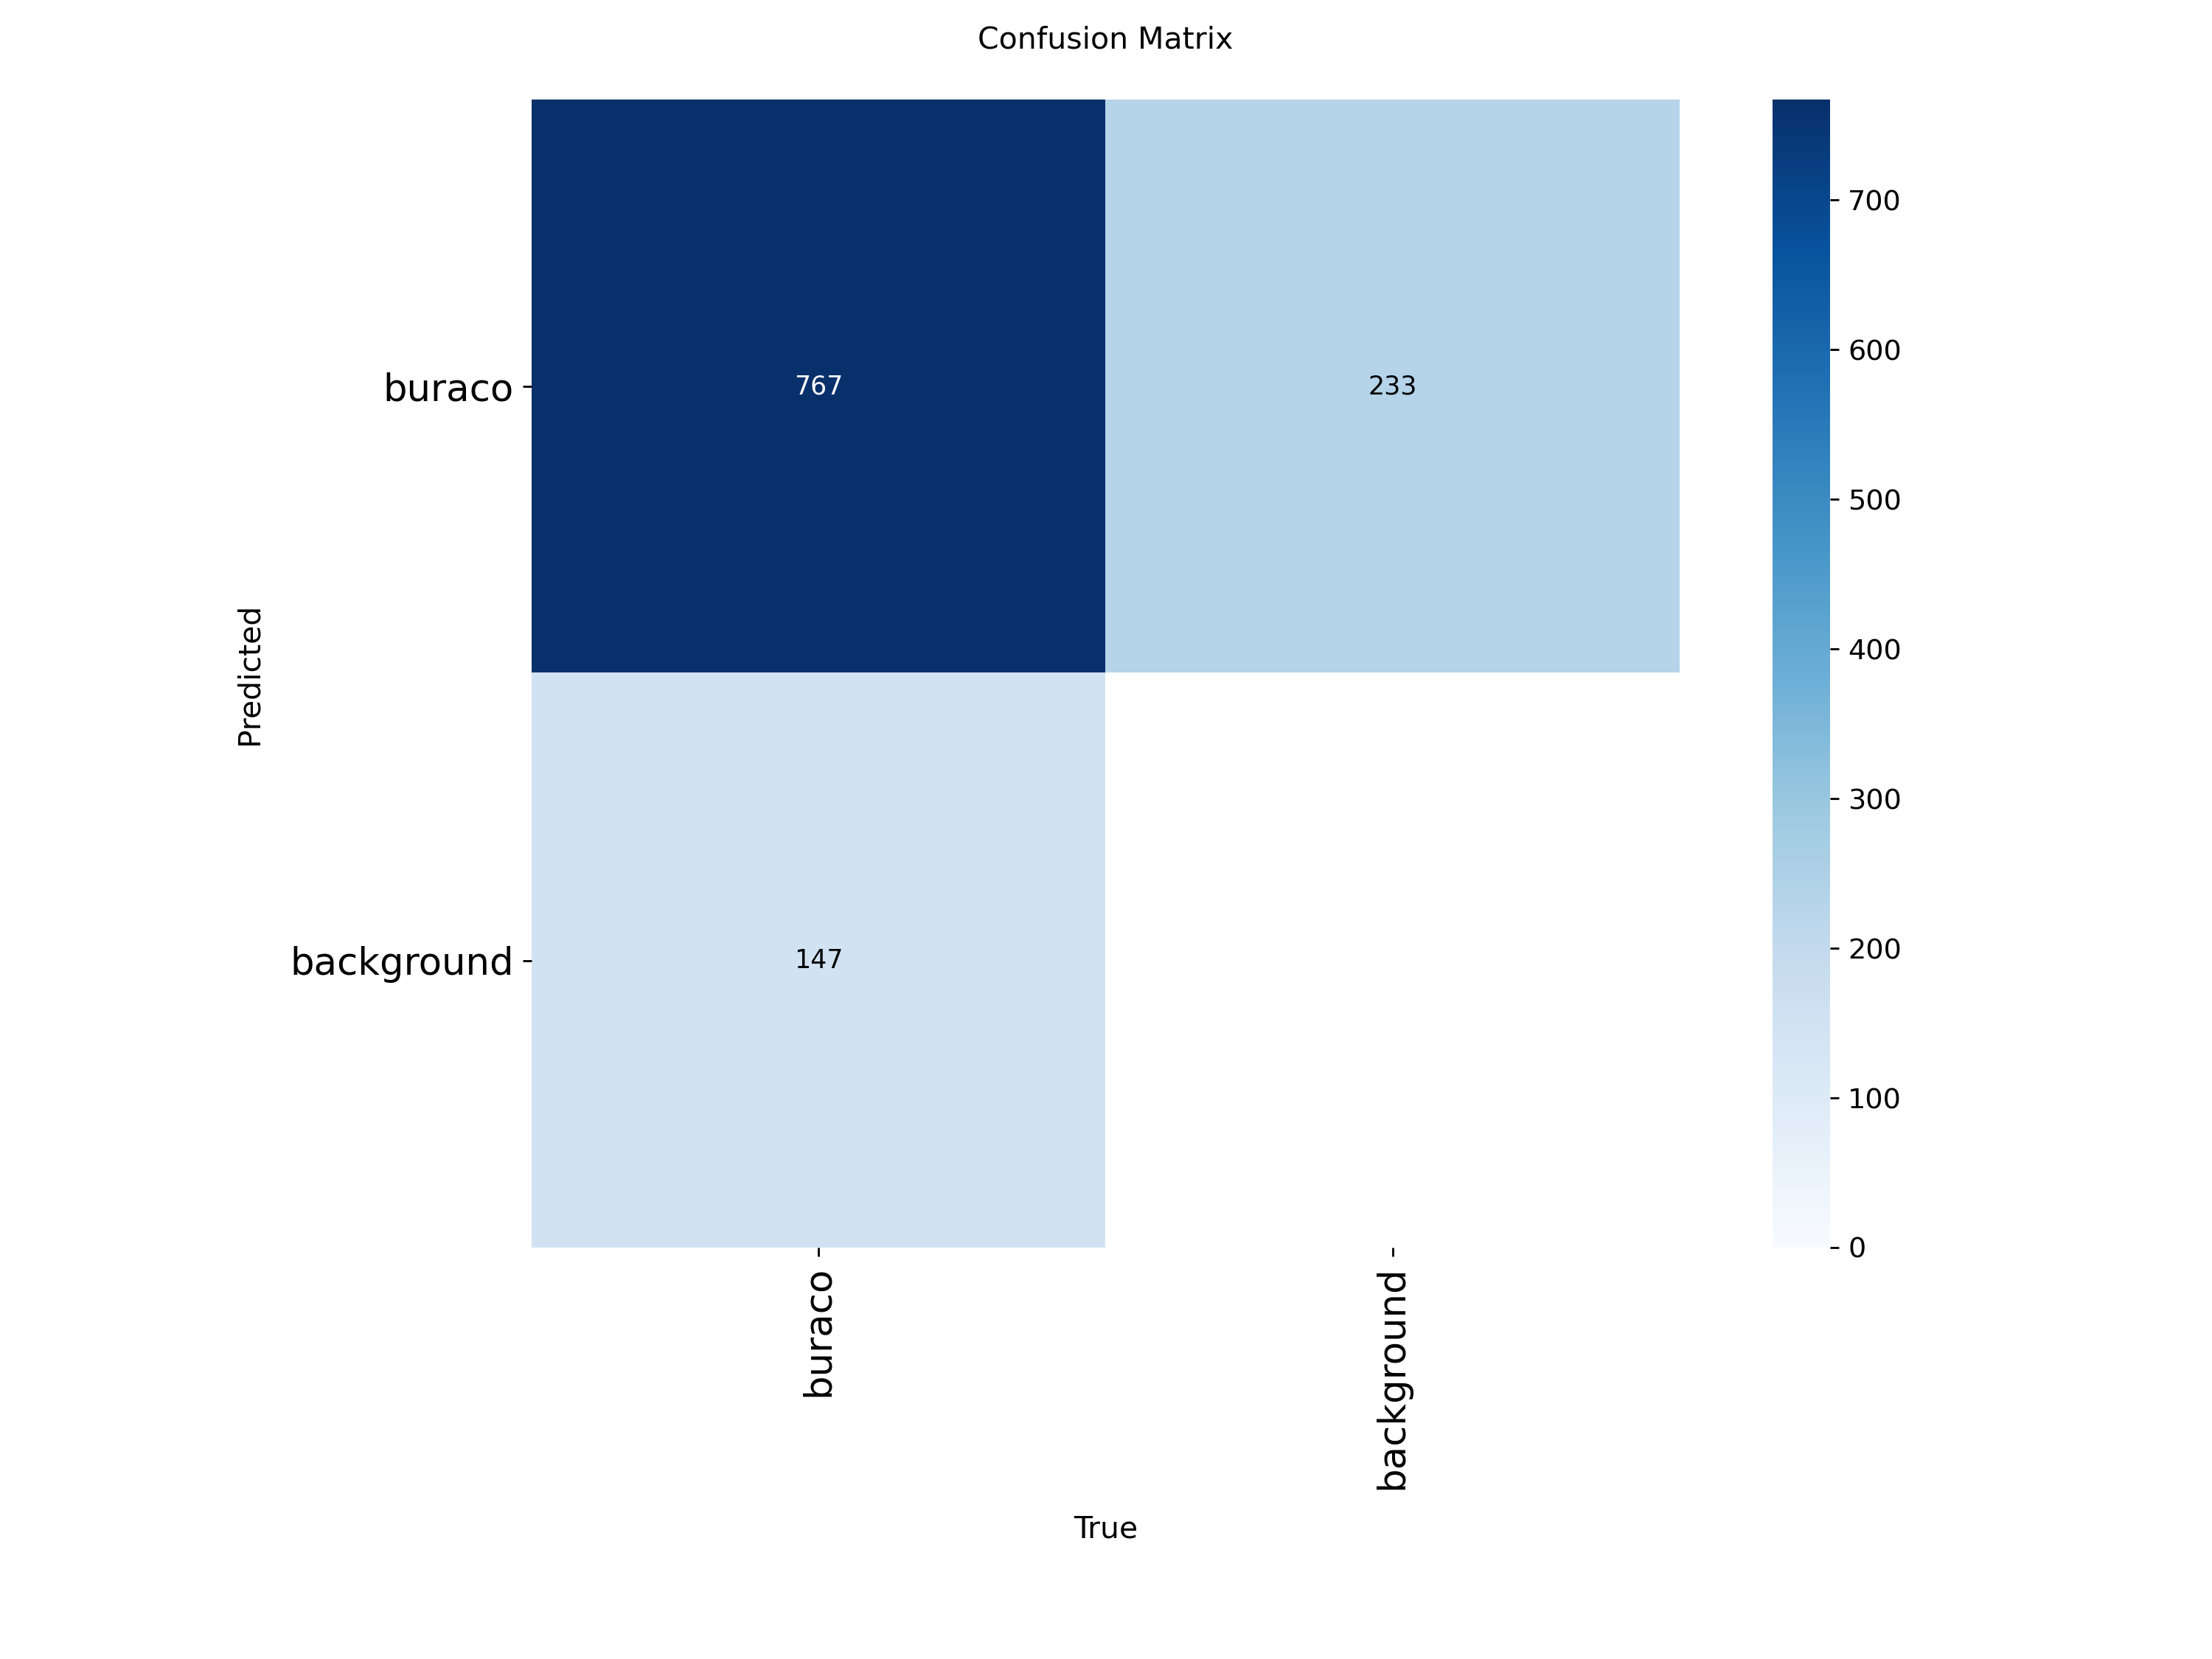

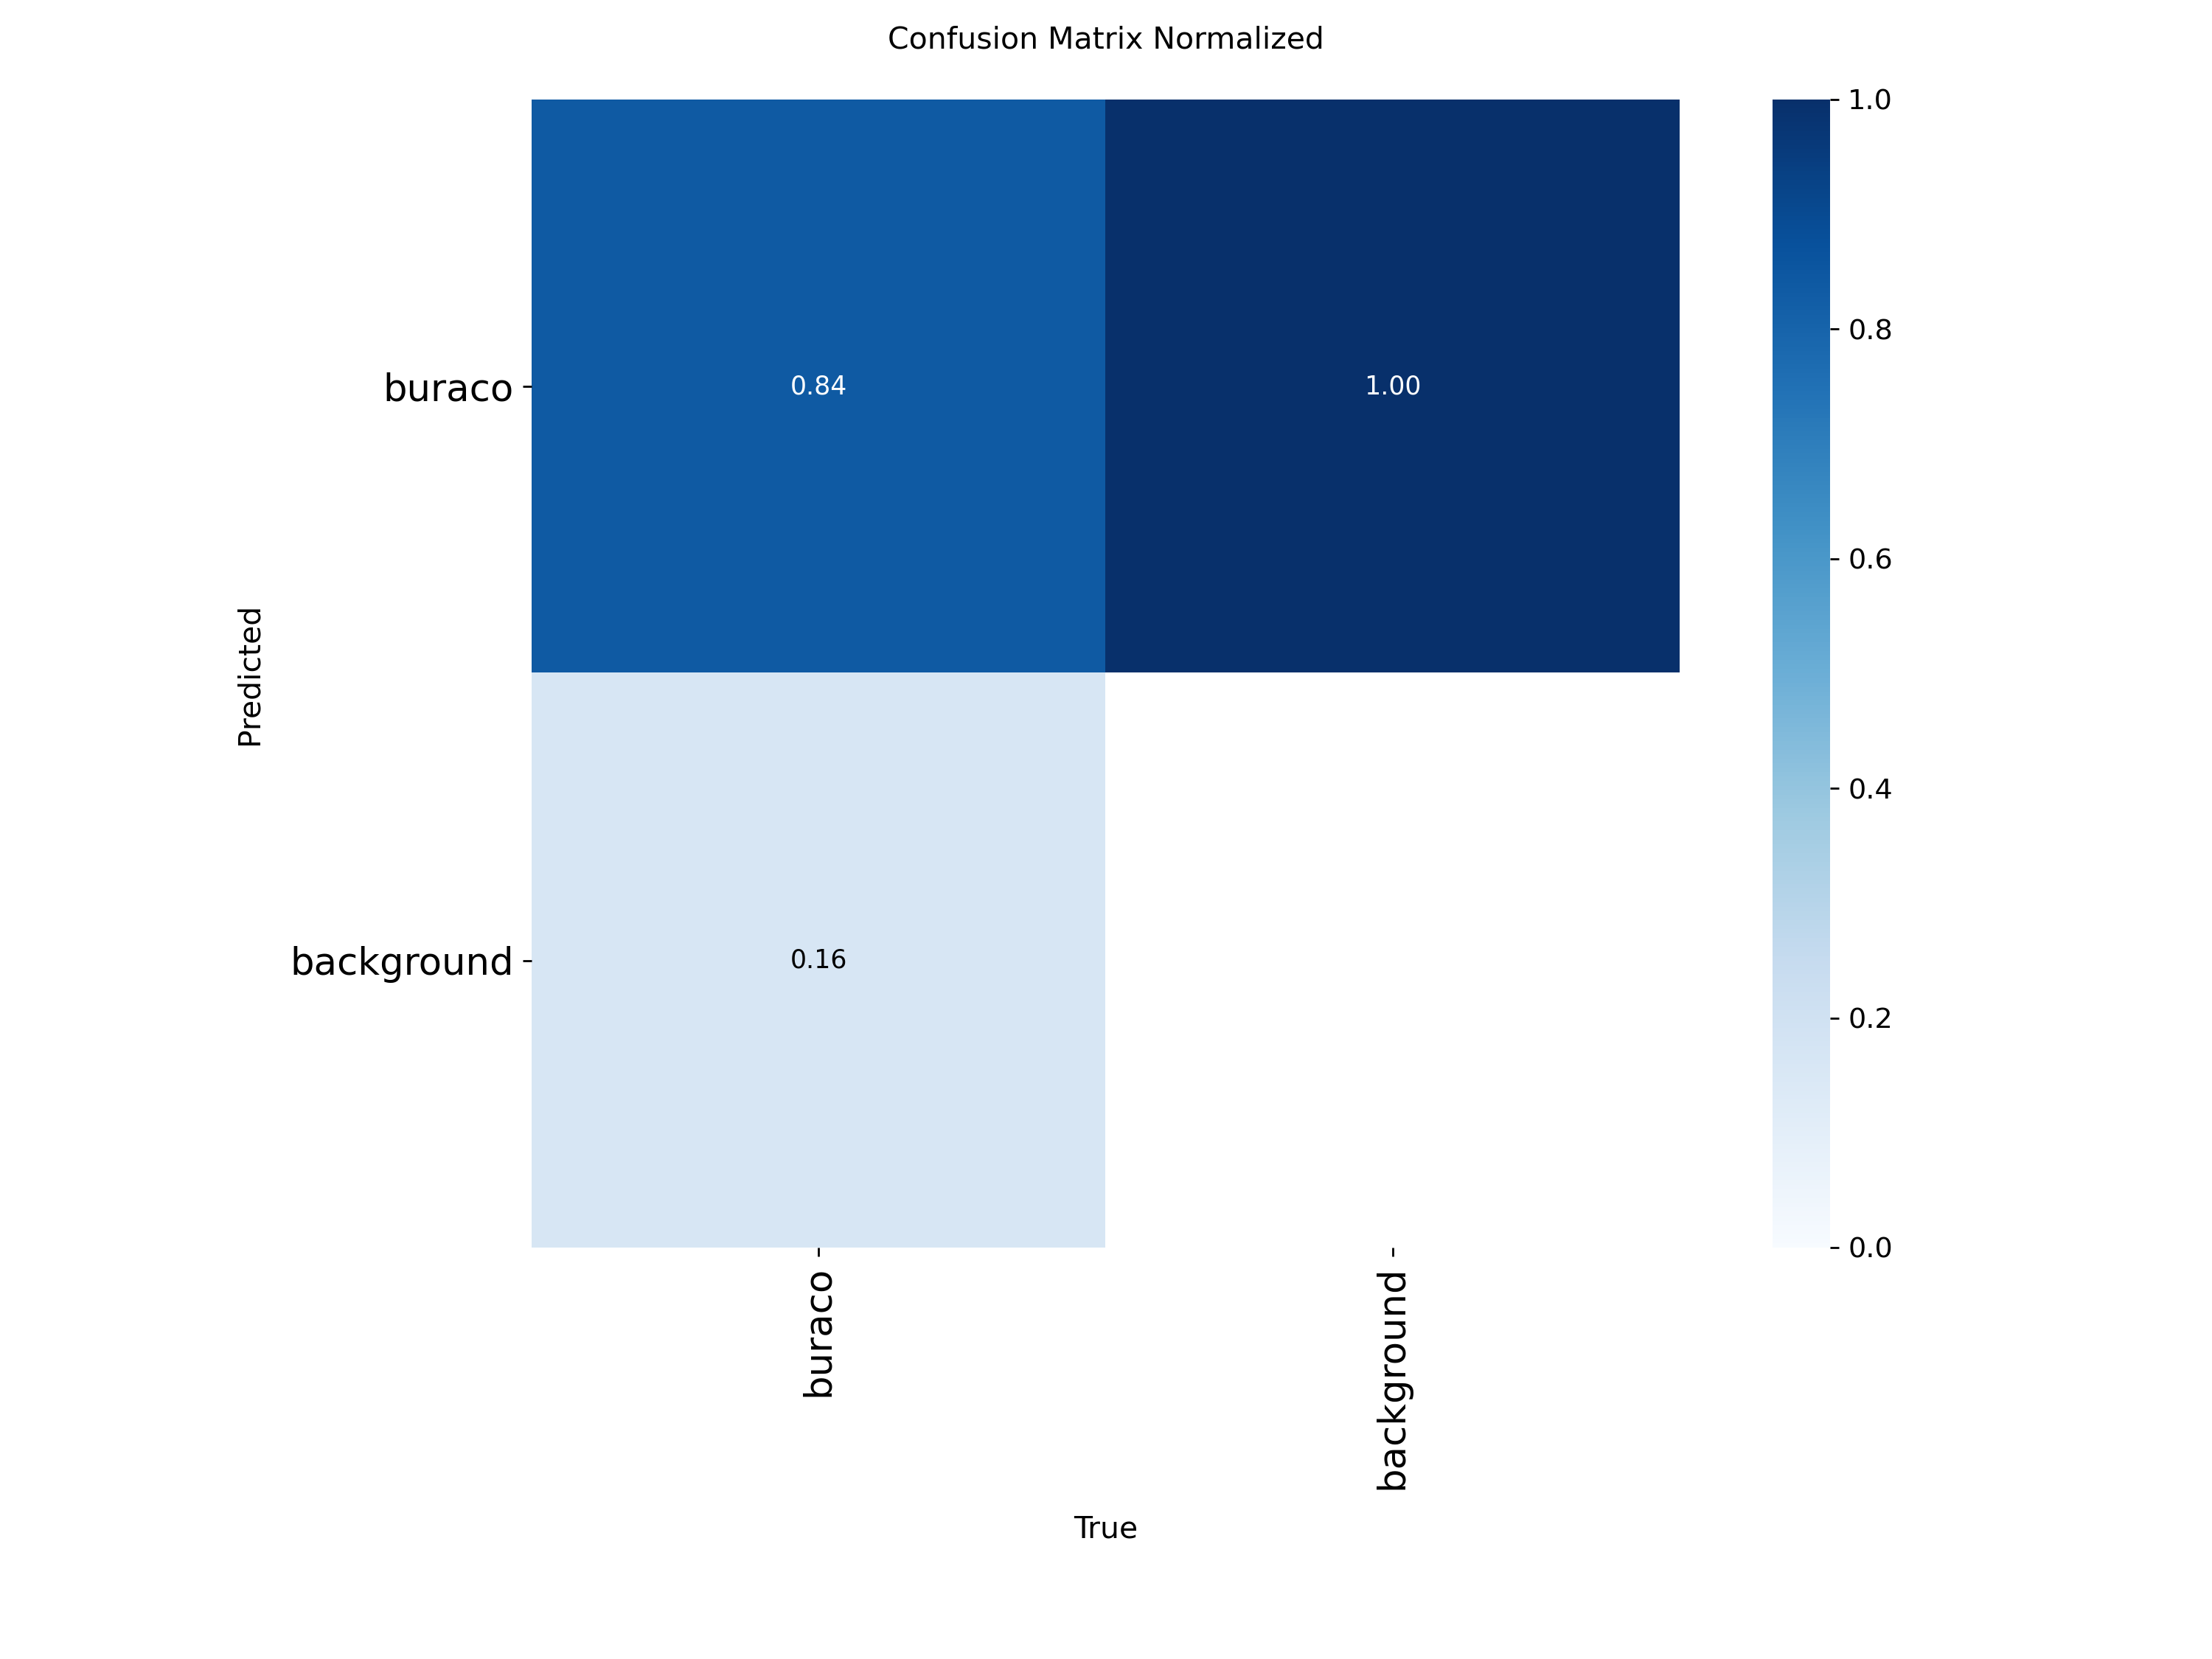

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
import torch, shutil
from ultralytics import YOLO
from IPython.display import Image, display
from google.colab import files

CAMINHO_MODELO = '/content/best (3).pt'
CAMINHO_YAML = '/content/data_fix.yaml'   # o yaml que funcionou (troque se usar outro dataset)

# 1) lê os parâmetros reais do treino, guardados dentro do best.pt
ckpt = torch.load(CAMINHO_MODELO, map_location='cpu', weights_only=False)
ta = ckpt.get('train_args', {})
imgsz = ta.get('imgsz', 640)
print("Parâmetros do treino:")
for k in ['epochs', 'patience', 'imgsz', 'batch', 'data', 'model']:
    print(f"  {k} = {ta.get(k)}")

# 2) roda a validação no teste com o mesmo imgsz do treino
model = YOLO(CAMINHO_MODELO)
resultados = model.val(
    data=CAMINHO_YAML,
    split='test',
    imgsz=imgsz,
    conf=0.25,        # limiar para a matriz de confusão
    plots=True,
    project='/content/avaliacao_pavimentai',
    name='matriz_conf025',
    exist_ok=True
)

print(f"\nPrecisão: {resultados.box.mp:.4f} | Recall: {resultados.box.mr:.4f} | "
      f"mAP50: {resultados.box.map50:.4f} | mAP50-95: {resultados.box.map:.4f}")

# 3) mostra e baixa as matrizes
for nome in ['confusion_matrix.png', 'confusion_matrix_normalized.png']:
    display(Image(filename=f'{resultados.save_dir}/{nome}'))

shutil.make_archive('matrizes', 'zip', resultados.save_dir)
files.download('matrizes.zip')

In [30]:
r2 = model.val(
    data='/content/data_fix.yaml',
    split='test',
    imgsz=640,
    plots=True,
    project='/content/avaliacao_pavimentai',
    name='metricas_conf_padrao',
    exist_ok=True
)
print(f"Precisão: {r2.box.mp:.4f} | Recall: {r2.box.mr:.4f} | mAP50: {r2.box.map50:.4f} | mAP50-95: {r2.box.map:.4f}")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2114.4±722.6 MB/s, size: 44.4 KB)
val: Scanning /content/dataset/dataset_unificado/test/labels.cache... 247 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 247/247 94.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.2it/s 3.8s
                   all        247        914      0.832      0.794      0.849      0.527
Speed: 1.6ms preprocess, 5.2ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/avaliacao_pavimentai/metricas_conf_padrao
Precisão: 0.8315 | Recall: 0.7943 | mAP50: 0.8490 | mAP50-95: 0.5272
